# Analysis of Factors Affecting Decorrelation Scale
This notebook analyzes how the decorrelation scale calculated in `08_Decorrelation_Analysis_v3.ipynb` relates to various climatological parameters.

In [1]:
import pandas as pd
import numpy as np
import gsw
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import sys
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

import warnings
warnings.filterwarnings('ignore')

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


## 1. Load Data

In [2]:
# Load main dataset
merged_df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
merged_df['zettaicode'] = merged_df['zettaicode'].astype(str).str.zfill(8)

# Load decorrelation scale results
decorr_path = ProjectPaths.get_subset_dir('Summer', 'bottom') / 'stations_decorrelation_scale.csv'
decorr_df = pd.read_csv(decorr_path)
if 'Station_ID' in decorr_df.columns:
    decorr_df['zettaicode'] = decorr_df['Station_ID'].astype(str).str.zfill(8)

print(f"Loaded merged data: {merged_df.shape}")
print(f"Loaded decorrelation data: {decorr_df.shape}")


Loaded merged data: (42326, 65)
Loaded decorrelation data: (124, 9)


## 2. Calculate Climatological Means

In [3]:
# Initialize DataFrame with all stations from merged_df
# Extract unique stations
stations = merged_df[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode').set_index('zettaicode')
print(f"Total unique stations: {len(stations)}")


Total unique stations: 127


In [4]:
def get_climatology(df, param, season, saisuipoin=None):
    mask = df['season'] == season
    if saisuipoin is not None:
        mask &= df['saisuipoin'] == saisuipoin
        
    # Group by station and calculate overall mean across all years
    return pd.to_numeric(df.loc[mask, param], errors='coerce').groupby(df.loc[mask, 'zettaicode']).mean()

# 1. Summer SST, SBT, SSS, SBS
sst = get_climatology(merged_df, 'wtemp', 'Summer', 1)
sbt = get_climatology(merged_df, 'wtemp', 'Summer', 2)
sss = get_climatology(merged_df, 'salt', 'Summer', 1)
sbs = get_climatology(merged_df, 'salt', 'Summer', 2)

# 2. Wind speed, Air temp, Chl-a
wind = get_climatology(merged_df, 'fusoku', 'Summer')
air_t = get_climatology(merged_df, 'temp', 'Winter')
chla = get_climatology(merged_df, 'chlorophyl', 'Spring')

# Compile into a DataFrame
result_df = stations.copy()
result_df['Mean_Summer_Surface_Temp'] = sst
result_df['Mean_Summer_Bottom_Temp'] = sbt
result_df['Mean_Summer_Surface_Salinity'] = sss
result_df['Mean_Summer_Bottom_Salinity'] = sbs
result_df['Mean_Summer_Wind_Speed'] = wind
result_df['Mean_Winter_Air_Temp'] = air_t
result_df['Mean_Spring_Chla'] = chla


## 3. Density Calculation using `gsw-python`

In [5]:
# Calculate Density (Sigma-0) from Absolute Salinity and Conservative Temperature
result_df['SA_surface'] = gsw.SA_from_SP(result_df['Mean_Summer_Surface_Salinity'], 0, result_df['longitude'], result_df['latitude'])
result_df['CT_surface'] = gsw.CT_from_t(result_df['SA_surface'], result_df['Mean_Summer_Surface_Temp'], 0)
result_df['Mean_Summer_Surface_Density'] = gsw.sigma0(result_df['SA_surface'], result_df['CT_surface'])

result_df['SA_bottom'] = gsw.SA_from_SP(result_df['Mean_Summer_Bottom_Salinity'], 0, result_df['longitude'], result_df['latitude'])
result_df['CT_bottom'] = gsw.CT_from_t(result_df['SA_bottom'], result_df['Mean_Summer_Bottom_Temp'], 0)
result_df['Mean_Summer_Bottom_Density'] = gsw.sigma0(result_df['SA_bottom'], result_df['CT_bottom'])

# Drop intermediate columns
result_df = result_df.drop(columns=['SA_surface', 'CT_surface', 'SA_bottom', 'CT_bottom', 'latitude', 'longitude'])


## 4. Join with Decorrelation Scale and Produce Output

The `result_df` dataframe summarizes the climatological mean of physical and biological parameters alongside the DO decorrelation scale for all 127 sampling stations.

In [6]:
# Merge Decorrelation Scale
decorr_df = decorr_df.set_index('zettaicode')

if 'Decorrelation_Scale_km' in decorr_df.columns:
    result_df = result_df.join(decorr_df[['Decorrelation_Scale_km']].rename(columns={'Decorrelation_Scale_km': 'decorrelation_scale'}))
elif 'decorrelation_scale' in decorr_df.columns:
    result_df = result_df.join(decorr_df[['decorrelation_scale']])
elif 'dx' in decorr_df.columns:
    result_df = result_df.join(decorr_df[['dx']].rename(columns={'dx': 'decorrelation_scale'}))

print("DataFrame containing the climatological mean of the specified parameters:")
display(result_df)


DataFrame containing the climatological mean of the specified parameters:


,Mean_Summer_Surface_Temp,Mean_Summer_Bottom_Temp,Mean_Summer_Surface_Salinity,Mean_Summer_Bottom_Salinity,Mean_Summer_Wind_Speed,Mean_Winter_Air_Temp,Mean_Spring_Chla,Mean_Summer_Surface_Density,Mean_Summer_Bottom_Density,decorrelation_scale
zettaicode,,,,,,,,,,
00002811,26.274419,22.427907,18.702791,30.617674,2.583333,9.387500,17.686047,10.709268,20.778539,4.539463
00002823,25.727907,21.562791,23.089070,31.745814,2.500000,9.366250,8.474419,14.157872,21.871771,7.523284
00000272,25.509302,21.500000,16.987907,31.300465,1.558442,7.896203,6.405952,9.646465,21.550824,0.459884
00002725,25.246512,22.104651,26.837674,32.058372,1.259740,7.397468,3.545349,17.116783,21.960026,8.890848
00000275,26.206977,20.755814,26.697442,31.950233,1.753247,8.535443,11.755294,16.723519,22.244059,9.509381
...,...,...,...,...,...,...,...,...,...,...
00038372,21.704762,20.976190,32.760476,32.872952,0.000000,9.253030,0.978049,22.603250,22.886789,22.475013
00034363,22.488095,21.540476,32.189286,32.392619,1.061538,8.703030,1.075610,21.952497,22.368997,13.931929
00044528,25.563636,19.627273,29.272727,33.185455,0.727273,7.377273,NaN,18.854482,23.479982,NaN


### Pearson correlation

In [7]:
# ── Pearson's Correlation: Decorrelation Scale vs. Each Parameter ──

from scipy import stats

# Define the parameter columns to correlate with decorrelation_scale
param_cols = [
    'Mean_Summer_Surface_Temp',
    'Mean_Summer_Bottom_Temp',
    'Mean_Summer_Surface_Salinity',
    'Mean_Summer_Bottom_Salinity',
    'Mean_Summer_Wind_Speed',
    'Mean_Winter_Air_Temp',
    'Mean_Spring_Chla',
    'Mean_Summer_Surface_Density',
    'Mean_Summer_Bottom_Density',
]

# Calculate Pearson's r and p-value for each parameter
corr_records = []
for col in param_cols:
    # Drop rows where either value is NaN
    valid = result_df[['decorrelation_scale', col]].dropna()
    n = len(valid)
    if n >= 3:  # need at least 3 data points
        r, p = stats.pearsonr(valid['decorrelation_scale'], valid[col])
    else:
        r, p = np.nan, np.nan
    corr_records.append({
        'Parameter': col,
        'Pearson_r': r,
        'p_value': p,
        'n': n,
        'Significant (p<0.05)': '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    })

corr_df = pd.DataFrame(corr_records).set_index('Parameter')
corr_df = corr_df.sort_values('p_value')

print("Pearson's Correlation: Decorrelation Scale vs. Each Parameter")
print("=" * 70)
display(corr_df)


Pearson's Correlation: Decorrelation Scale vs. Each Parameter


,Pearson_r,p_value,n,Significant (p<0.05)
Parameter,,,,
Mean_Summer_Surface_Temp,-0.368041,0.000026,124,***
Mean_Summer_Bottom_Density,0.309128,0.000477,124,***
Mean_Summer_Surface_Density,0.303559,0.000610,124,***
Mean_Summer_Bottom_Temp,-0.299969,0.000712,124,***
Mean_Winter_Air_Temp,0.277054,0.001839,124,**
Mean_Summer_Bottom_Salinity,0.276380,0.001889,124,**
Mean_Spring_Chla,-0.273766,0.002093,124,**
Mean_Summer_Surface_Salinity,0.266226,0.002802,124,**
Mean_Summer_Wind_Speed,-0.125294,0.165578,124,


### Random forest regressor

Samples used (after dropping NaN): 124 / 127
Features: 9
Training R²:          0.8147
LOO-CV R² (mean±std): nan ± nan
LOO-CV RMSE (mean):   5.9637


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30


Feature Importance Ranking:


,MDI_Importance,Permutation_Importance
Mean_Summer_Surface_Density,0.207902,0.255618
Mean_Summer_Wind_Speed,0.115100,0.178742
Mean_Winter_Air_Temp,0.137524,0.171539
Mean_Summer_Surface_Salinity,0.138357,0.142038
Mean_Spring_Chla,0.103765,0.126115
Mean_Summer_Surface_Temp,0.099423,0.105278
Mean_Summer_Bottom_Salinity,0.064330,0.070398
Mean_Summer_Bottom_Temp,0.071845,0.063233
Mean_Summer_Bottom_Density,0.061753,0.056426


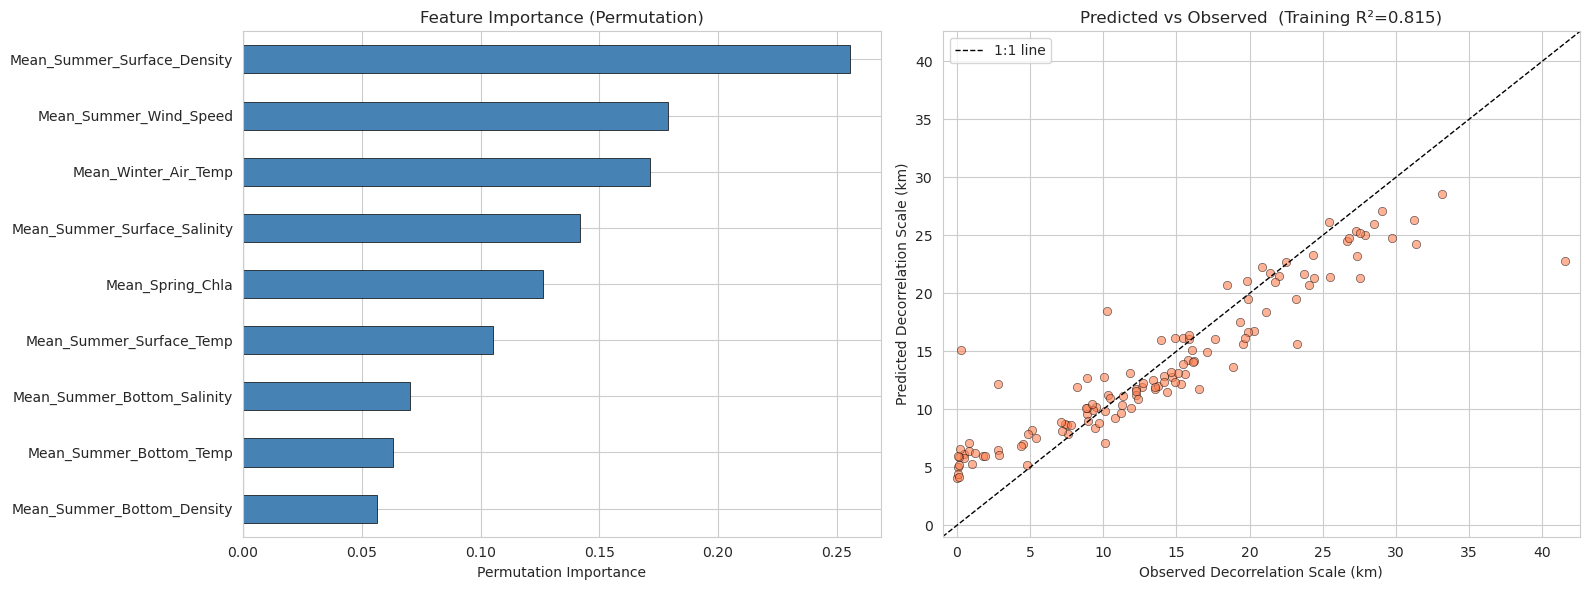

In [8]:
# ── Random Forest Regressor: Predict Decorrelation Scale from Parameters ──

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

# Prepare data — drop rows with any NaN in features or target
model_df = result_df[param_cols + ['decorrelation_scale']].dropna()
X = model_df[param_cols]
y = model_df['decorrelation_scale']

print(f"Samples used (after dropping NaN): {len(X)} / {len(result_df)}")
print(f"Features: {X.shape[1]}")
print("=" * 70)

# ── Train Random Forest ──
rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
rf.fit(X, y)

# ── Cross-Validation (Leave-One-Out for small dataset) ──
loo = LeaveOneOut()
cv_scores = cross_val_score(rf, X, y, cv=loo, scoring='r2')
cv_rmse = cross_val_score(rf, X, y, cv=loo, scoring='neg_root_mean_squared_error')

print(f"Training R²:          {rf.score(X, y):.4f}")
print(f"LOO-CV R² (mean±std): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"LOO-CV RMSE (mean):   {-cv_rmse.mean():.4f}")
print("=" * 70)

# ── Feature Importance (MDI + Permutation) ──
# 1. Mean Decrease in Impurity (built-in)
mdi_importance = pd.Series(rf.feature_importances_, index=param_cols, name='MDI_Importance')

# 2. Permutation importance (more robust)
perm_result = permutation_importance(rf, X, y, n_repeats=30, random_state=42, n_jobs=-1)
perm_importance = pd.Series(perm_result.importances_mean, index=param_cols, name='Permutation_Importance')

importance_df = pd.DataFrame({
    'MDI_Importance': mdi_importance,
    'Permutation_Importance': perm_importance,
}).sort_values('Permutation_Importance', ascending=False)

print("\nFeature Importance Ranking:")
display(importance_df)

# ── Visualisation ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# (a) Feature importance bar chart (permutation-based)
importance_df['Permutation_Importance'].sort_values().plot.barh(
    ax=axes[0], color='steelblue', edgecolor='black', linewidth=0.5
)
axes[0].set_xlabel('Permutation Importance')
axes[0].set_title('Feature Importance (Permutation)')
axes[0].axvline(x=0, color='grey', linestyle='--', linewidth=0.8)

# (b) Predicted vs. Observed scatter
y_pred = rf.predict(X)
axes[1].scatter(y, y_pred, alpha=0.6, edgecolors='black', linewidth=0.5, color='coral')
lims = [min(y.min(), y_pred.min()) - 1, max(y.max(), y_pred.max()) + 1]
axes[1].plot(lims, lims, 'k--', linewidth=1, label='1:1 line')
axes[1].set_xlabel('Observed Decorrelation Scale (km)')
axes[1].set_ylabel('Predicted Decorrelation Scale (km)')
axes[1].set_title(f'Predicted vs Observed  (Training R²={rf.score(X, y):.3f})')
axes[1].legend()
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)

plt.tight_layout()
plt.show()
